# 31 · Figures for the report

The picture figures of the report, made from the project's own results (no new data):

- **Figure 1:** a screenshot of the offline dashboard (notebook 29), India view.
- **Figure 2:** a static map for print, primary level only: (a) the share of children living more than 1 km from the
  nearest primary school and (b) primary school places per child (E2SFCA, norm-based), both for India districts,
  and (c) the share beyond 1 km for Kerala local bodies (lower primary). Panels (a) and (b) together show that
  distance and capacity are different problems: Bihar is light in (a) but dark in (b). Values come from the D6 result tables
  (notebook 27: `school_india_by_district.csv`, `school_kerala_by_local_body.csv`), shapes from the data lake
  (geoBoundaries and OpenStreetMap). The dashboard uses 7 equal-count colour classes; this print map uses 5 fixed
  classes so the numbers are easy to read. Grey: incomplete UDISE list (Delhi, DNH & DD) or no OpenStreetMap
  local body (7 in Kerala).

- **Pattern map:** (a) the five K-Means area types of India sub-districts and (b) the Gi* clusters at primary level
  (hot spots of children beyond 1 km, cold spots of few seats per child), from the notebook 28 results.
- **Benchmark chart:** (a) run time vs data size, plain Python vs Spark + Sedona, and (b) Spark run time vs cores,
  from the notebook 30 results (`benchmarks.csv`).

Outputs: `REPORT/figures/`.

**Check:** the district and local-body tables add up to the same India and Kerala totals as the state and district
tables quoted in the report. The pattern map checks its counts against the notebook 28 results
(5,890 sub-districts, 2,737 crowded, 952 hot and 606 cold spots).

## Project folder (laptop or Colab)

In [1]:
# Project folder. Laptop: open the notebook from "PROJECTS IPYNB" (or the project root).
# Google Colab: upload the project folder to Google Drive ("My Drive") and set its name below.
from pathlib import Path
import sys
PROJECT_FOLDER = "Distance-Capacity-and-Inequality-in-Access-to-Government-and-Aided-Schools"  # Colab only: folder name inside My Drive
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive") / PROJECT_FOLDER
else:
    PROJECT = Path.cwd().parent if Path.cwd().name in ("notebooks", "PROJECTS IPYNB") else Path.cwd()
assert (PROJECT / "scripts").is_dir(), f"project folder not found: {PROJECT}"
sys.path.insert(0, str(PROJECT / "scripts"))

In [2]:
# Colab only: install packages that Colab does not have by default (does nothing on the laptop)
if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rapidfuzz", "pymupdf", "pyogrio", "rasterio"], check=True)

## Settings

In [3]:
import shutil
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.patches import Patch

sys.path.insert(0, str(PROJECT / "scripts" / "bigdata"))
import population_cells as pc

SILVER = PROJECT / "data" / "lake" / "silver"
RES = PROJECT / "FINAL COMPLETE DATASET" / "results" / "schools"
DASH = PROJECT / "FINAL COMPLETE DATASET" / "results" / "dashboard" / "school_access_dashboard.html"
OUT = PROJECT / "REPORT" / "figures"
OUT.mkdir(parents=True, exist_ok=True)

# Fixed classes for print (the dashboard uses 7 equal-count classes instead); one hue, light = better
BINS = [0, 5, 10, 20, 40, 101]
LABELS = ["under 5 %", "5-10 %", "10-20 %", "20-40 %", "40 % or more"]
COLS = ["#fee5d9", "#fcae91", "#fb6a4a", "#de2d26", "#a50f15"]
GREY = "#d9d9d9"
# Places per child (capacity): a second hue so it is not mixed up with distance; dark = fewer places = worse
A_BINS = [0, 0.5, 0.75, 1.0, 1.5, np.inf]
A_LABELS = ["under 0.5", "0.5-0.75", "0.75-1", "1-1.5", "1.5 or more"]
A_COLS = ["#08306b", "#2171b5", "#6baed6", "#c6dbef", "#eff3ff"]


def classify(v, bins=BINS):
    return pd.cut(v, bins, right=False, labels=False)


def shapes(code_col, tol):
    g = pc.load_units(SILVER, code_col).set_crs(4326, allow_override=True)
    g["geometry"] = g.geometry.simplify(tol, preserve_topology=True)
    return g

## Values per area

In [4]:
# Values per area, read from the D6 result tables (notebook 27): share of children beyond 1 km, weighted by children
d = pd.read_csv(RES / "school_india_by_district.csv")
d["w"] = d["beyond_norm_%_primary"] * d["children_primary"]
d["wa"] = d["a_main_primary"] * d["children_primary"]
agg = d.groupby("district_code").agg(w=("w", "sum"), wa=("wa", "sum"), c=("children_primary", "sum"),
                                     bad=("udise_incomplete_primary", "max"))
agg["v"] = agg.w / agg.c  # a district split over two state rows (border cells) is combined
agg["a"] = agg.wa / agg.c  # places per child (norm-based), children-weighted
dist = shapes("district_code", 0.01).merge(agg, left_on="code", right_index=True, how="left")
states = shapes("state_code", 0.01)

k = pd.read_csv(RES / "school_kerala_by_local_body.csv")
k["w"] = k["beyond_norm_%_lp"] * k["children_lp"]
ka = k[k.local_body_code > 0].groupby("local_body_code").agg(w=("w", "sum"), c=("children_lp", "sum"))
ka["v"] = ka.w / ka.c
lbs = shapes("local_body_code", 0.0005).merge(ka, left_on="code", right_index=True, how="left")
kerala = states.query("unit_name == 'Kerala'")

ok = dist[dist.v.notna() & ~dist.bad.fillna(False).astype(bool)]
kv = lbs[lbs.v.notna()]
print("districts mapped", len(ok), "of", len(dist), "| Kerala local bodies", len(kv), "of", len(lbs))
print("median: India districts %.1f %%, Kerala local bodies %.1f %%" % (ok.v.median(), kv.v.median()))

districts mapped 721 of 735 | Kerala local bodies 1027 of 1027
median: India districts 15.3 %, Kerala local bodies 18.9 %


## Checks

In [5]:
# Checks: the area tables add up to the same totals as the state / district tables used in the report
s = pd.read_csv(RES / "school_india_by_state.csv")
india = (s["beyond_norm_%_primary"] * s["children_primary"]).sum() / s["children_primary"].sum()
india_d = d.w.sum() / d.children_primary.sum()
kd = pd.read_csv(RES / "school_kerala_by_district.csv")
ker = (kd["beyond_norm_%_lp"] * kd["children_lp"]).sum() / kd["children_lp"].sum()
ker_lb = k.w.sum() / k.children_lp.sum()
print(f"India primary beyond 1 km: states {india:.2f} %, districts {india_d:.2f} %")
print(f"Kerala lower primary beyond 1 km: districts {ker:.2f} %, local bodies {ker_lb:.2f} %")
a_s = (s["a_main_primary"] * s["children_primary"]).sum() / s["children_primary"].sum()
a_d = d.wa.sum() / d.children_primary.sum()
print(f"India primary places per child: states {a_s:.3f}, districts {a_d:.3f}")
bihar = s.loc[s.state == "Bihār"].iloc[0]
print(f"Bihar: {bihar['beyond_norm_%_primary']:.1f} % beyond 1 km, {bihar['a_main_primary']:.2f} places per child")
assert abs(india - india_d) < 0.1 and abs(ker - ker_lb) < 0.1 and abs(a_s - a_d) < 0.005, "area tables do not add up"
assert len(ok) >= 700 and len(kv) == len(lbs), "areas missing from the map"
print("checks passed")

India primary beyond 1 km: states 15.98 %, districts 15.98 %
Kerala lower primary beyond 1 km: districts 19.29 %, local bodies 19.29 %
India primary places per child: states 1.101, districts 1.101
Bihar: 2.8 % beyond 1 km, 0.56 places per child
checks passed


## Figure 2: map of children beyond 1 km

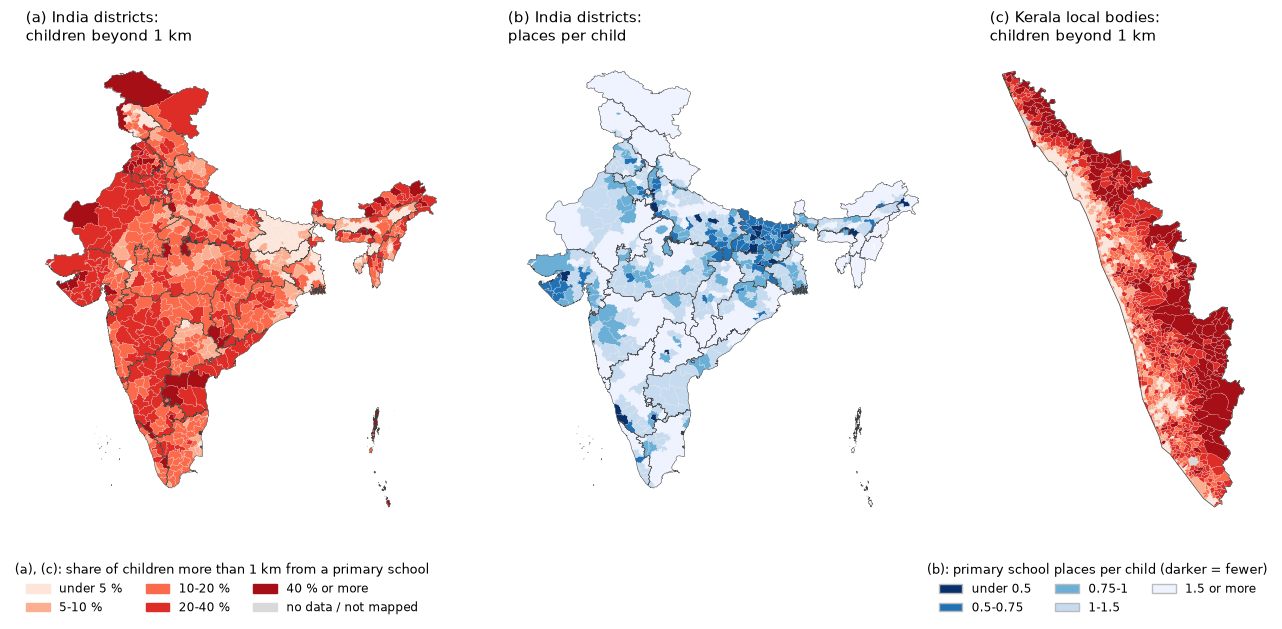

saved C:\Users\ASUS\Desktop\sem3\BIG SPATIAL DATA\PROJECT- SPATIAL INEQUALITY ASESSMENT\REPORT\figures\fig_map_beyond_1km.png


In [6]:
# Figure 2 of the report, primary level only: (a) distance and (b) places per child for India districts,
# (c) distance for Kerala local bodies (lower primary)
fig, ax = plt.subplots(1, 3, figsize=(13, 6.4), gridspec_kw={"width_ratios": [1.3, 1.3, 0.85]})
for a in ax:
    a.set_axis_off()
dist.plot(ax=ax[0], color=GREY, linewidth=0)  # grey = UDISE list incomplete (Delhi, DNH & DD)
ok.plot(ax=ax[0], color=[COLS[int(c)] for c in classify(ok.v)], linewidth=0.1, edgecolor="white")
states.boundary.plot(ax=ax[0], color="#404040", linewidth=0.35)
ax[0].set_title("(a) India districts:\nchildren beyond 1 km", fontsize=11, loc="left")

dist.plot(ax=ax[1], color=GREY, linewidth=0)
ok.plot(ax=ax[1], color=[A_COLS[int(c)] for c in classify(ok.a, A_BINS)], linewidth=0.1, edgecolor="white")
states.boundary.plot(ax=ax[1], color="#404040", linewidth=0.35)
ax[1].set_title("(b) India districts:\nplaces per child", fontsize=11, loc="left")

kerala.plot(ax=ax[2], color=GREY, linewidth=0)  # grey = the 7 local bodies with no OpenStreetMap boundary
kv.plot(ax=ax[2], color=[COLS[int(c)] for c in classify(kv.v)], linewidth=0.1, edgecolor="white")
kerala.boundary.plot(ax=ax[2], color="#404040", linewidth=0.5)
ax[2].set_title("(c) Kerala local bodies:\nchildren beyond 1 km", fontsize=11, loc="left")

dist_h = [Patch(color=c, label=l) for c, l in zip(COLS, LABELS)]
cap_h = [Patch(facecolor=c, label=l, edgecolor="#bbbbbb") for c, l in zip(A_COLS, A_LABELS)]
grey_h = [Patch(color=GREY, label="no data / not mapped")]
fig.legend(handles=dist_h + grey_h, loc="lower left", bbox_to_anchor=(0.01, 0.0), ncol=3, frameon=False, fontsize=8.5,
           title="(a), (c): share of children more than 1 km from a primary school", title_fontsize=9)
fig.legend(handles=cap_h, loc="lower right", bbox_to_anchor=(0.99, 0.0), ncol=3, frameon=False, fontsize=8.5,
           title="(b): primary school places per child (darker = fewer)", title_fontsize=9)
fig.subplots_adjust(left=0.01, right=0.99, top=0.9, bottom=0.15, wspace=0.02)
fig.savefig(OUT / "fig_map_beyond_1km.png", dpi=200, facecolor="white")
plt.show()
print("saved", OUT / "fig_map_beyond_1km.png")

## Figure 1: dashboard screenshot

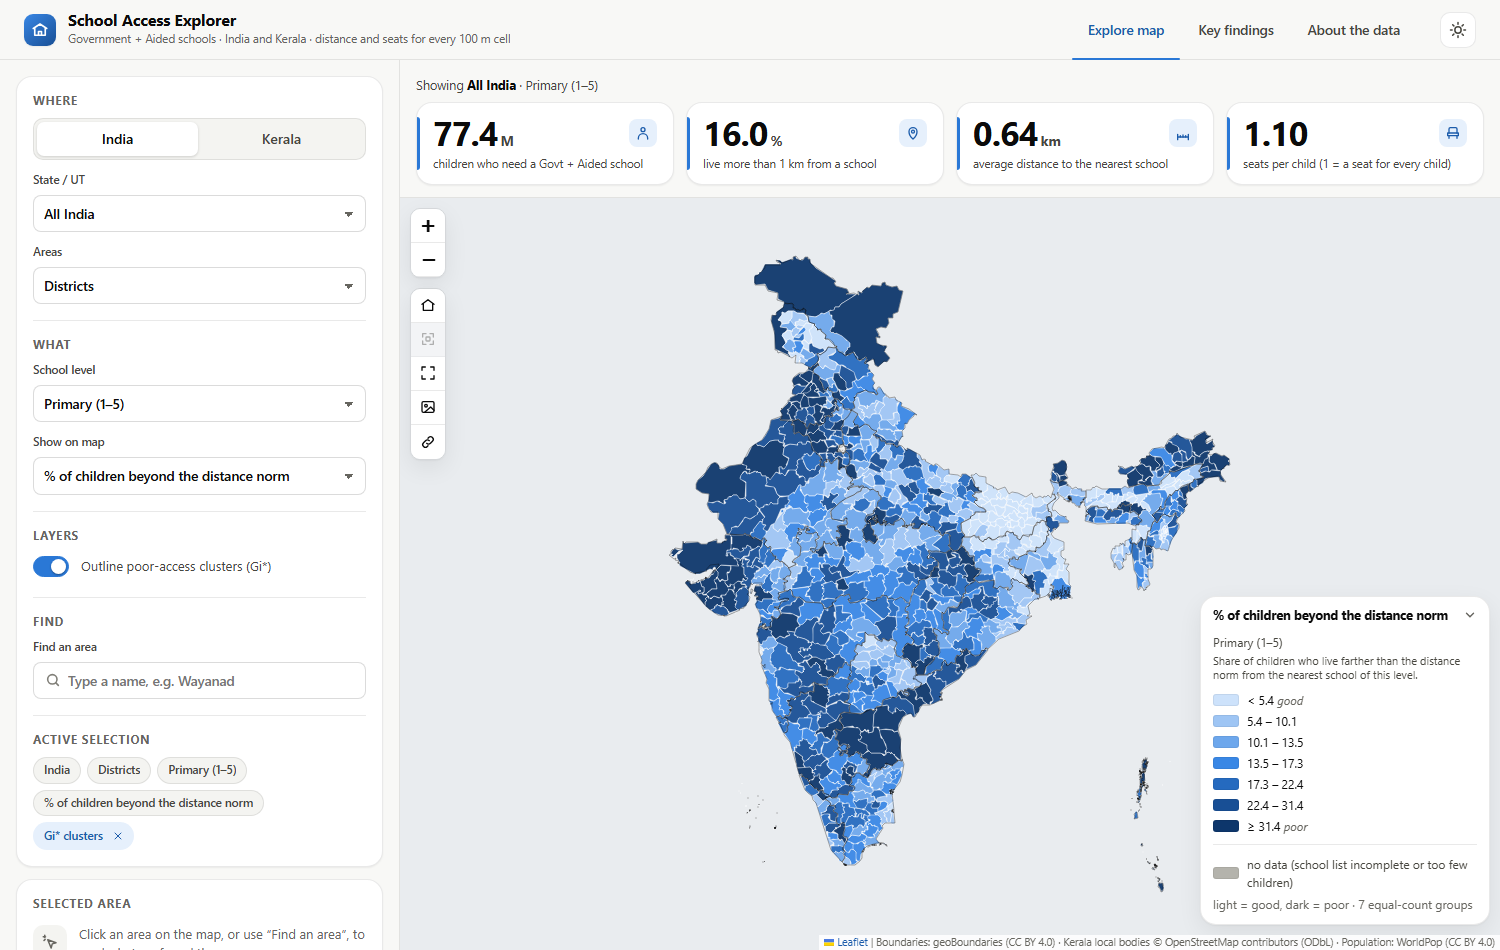

dashboard screenshot: C:\Users\ASUS\Desktop\sem3\BIG SPATIAL DATA\PROJECT- SPATIAL INEQUALITY ASESSMENT\REPORT\figures\fig_dashboard.png


In [7]:
# Figure 1 of the report: a screenshot of the dashboard (notebook 29), India view, taken with headless Edge on Windows.
# In Colab (no Edge) the saved screenshot is shown instead.
shot = OUT / "fig_dashboard.png"
edge = next((p for p in [Path(r"C:/Program Files (x86)/Microsoft/Edge/Application/msedge.exe"),
                         Path(r"C:/Program Files/Microsoft/Edge/Application/msedge.exe")] if p.exists()), None)
if edge and DASH.exists():
    prof = PROJECT / "data" / "tmp" / "edge_profile"
    subprocess.run([str(edge), "--headless=new", "--disable-gpu", "--hide-scrollbars", f"--user-data-dir={prof}",
                    "--window-size=1500,950", "--virtual-time-budget=15000", f"--screenshot={shot}", DASH.as_uri() + "#theme=light"],
                   timeout=120, capture_output=True)
    shutil.rmtree(prof, ignore_errors=True)
assert shot.exists(), "no dashboard screenshot"
display(Image(filename=str(shot), width=900))
print("dashboard screenshot:", shot)

## Pattern map: area types and Gi* clusters

area types: {'Crowded: near but few seats': 2737, 'Well served': 1882, 'Higher secondary far': 796, 'Far from primary school': 415, 'Remote: far at every level': 60} | Gi* primary: hot 952 cold 606 both 58


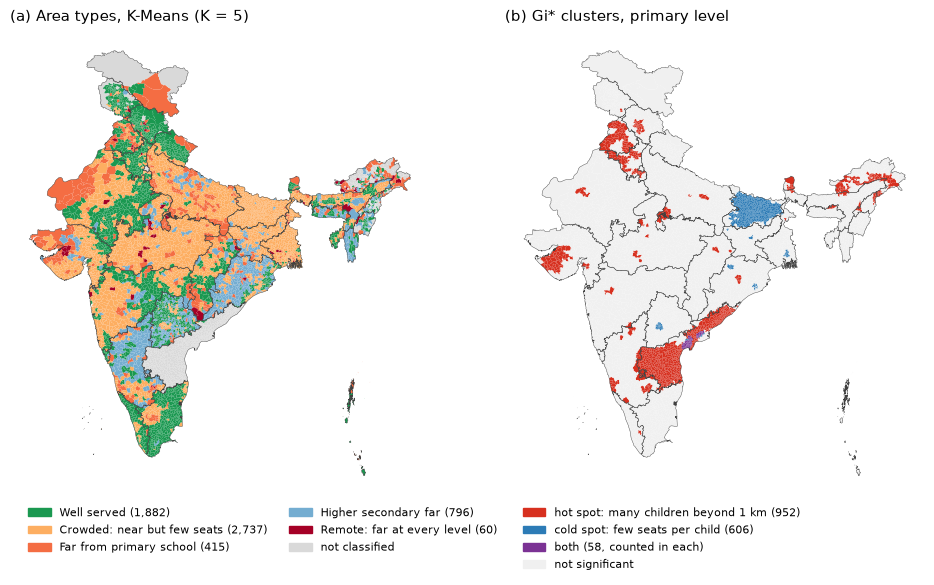

saved C:\Users\ASUS\Desktop\sem3\BIG SPATIAL DATA\PROJECT- SPATIAL INEQUALITY ASESSMENT\REPORT\figures\fig_area_types_hotspots.png


In [8]:
# Pattern map: (a) K-Means area types (notebook 28), (b) Gi* clusters at primary level (notebook 28), India sub-districts.
# Area-type names follow the same rule as the dashboard (notebook 29), so the names match everywhere.
types = pd.read_csv(RES / "school_area_types_india_subdistrict.csv")
prof = pd.read_csv(RES / "school_area_type_profiles.csv").set_index("cluster")
LVS = ["primary", "upper_primary", "secondary", "higher_secondary"]
names, left = {}, list(prof.index)
names[prof[[f"beyond_norm_%_{l}" for l in LVS]].mean(axis=1).idxmax()] = "Remote: far at every level"
left = [c for c in left if c not in names]
names[prof.loc[left, "beyond_norm_%_primary"].idxmax()] = "Far from primary school"
left = [c for c in left if c not in names]
names[prof.loc[left, "beyond_norm_%_higher_secondary"].idxmax()] = "Higher secondary far"
left = [c for c in left if c not in names]
names[prof.loc[left, "a_main_primary"].idxmin()] = "Crowded: near but few seats"
left = [c for c in left if c not in names]
assert len(left) == 1 and len(prof) == 5
names[left[0]] = "Well served"
types["type"] = types["cluster"].map(names)
TYPEC = {"Well served": "#1a9850", "Crowded: near but few seats": "#fdae61", "Far from primary school": "#f46d43",
         "Higher secondary far": "#74add1", "Remote: far at every level": "#a50026"}
counts = types["type"].value_counts()
h = pd.read_csv(RES / "school_hotspots_india_subdistrict.csv").query("level == 'primary'")
hot = set(h.query("variable == 'beyond_norm_%' and spot == 'hot'").subdistrict_code)    # many children beyond 1 km
cold = set(h.query("variable == 'a_main' and spot == 'cold'").subdistrict_code)        # few seats per child
both = hot & cold
print("area types:", counts.to_dict(), "| Gi* primary: hot", len(hot), "cold", len(cold), "both", len(both))
assert counts.sum() == 5890 and counts["Crowded: near but few seats"] == 2737 and len(hot) == 952 and len(cold) == 606

sub = shapes("subdistrict_code", 0.01)
sub_t = sub.merge(types[["subdistrict_code", "type"]], left_on="code", right_on="subdistrict_code", how="left")
fig, ax = plt.subplots(1, 2, figsize=(10, 6.0))
for a in ax:
    a.set_axis_off()
sub_t.plot(ax=ax[0], color=[TYPEC.get(t, GREY) for t in sub_t["type"]], linewidth=0)
states.boundary.plot(ax=ax[0], color="#404040", linewidth=0.3)
ax[0].set_title("(a) Area types, K-Means (K = 5)", fontsize=11, loc="left")
ax[0].legend(handles=[Patch(color=c, label=f"{t} ({counts[t]:,})") for t, c in TYPEC.items()] + [Patch(color=GREY, label="not classified")],
             loc="upper left", bbox_to_anchor=(0.02, 0.0), fontsize=8, frameon=False, ncol=2)
col = ["#7b3294" if c in both else "#d7301f" if c in hot else "#2c7bb6" if c in cold else "#f0f0f0" for c in sub["code"]]
sub.plot(ax=ax[1], color=col, linewidth=0)
states.boundary.plot(ax=ax[1], color="#404040", linewidth=0.3)
ax[1].set_title("(b) Gi* clusters, primary level", fontsize=11, loc="left")
ax[1].legend(handles=[Patch(color="#d7301f", label=f"hot spot: many children beyond 1 km ({len(hot):,})"),
                      Patch(color="#2c7bb6", label=f"cold spot: few seats per child ({len(cold):,})"),
                      Patch(color="#7b3294", label=f"both ({len(both):,}, counted in each)"),
                      Patch(color="#f0f0f0", label="not significant")],
             loc="upper left", bbox_to_anchor=(0.02, 0.0), fontsize=8, frameon=False)
fig.subplots_adjust(left=0.01, right=0.99, top=0.95, bottom=0.17, wspace=0.02)
fig.savefig(OUT / "fig_area_types_hotspots.png", dpi=200, facecolor="white")
plt.show()
print("saved", OUT / "fig_area_types_hotspots.png")

## Benchmark chart

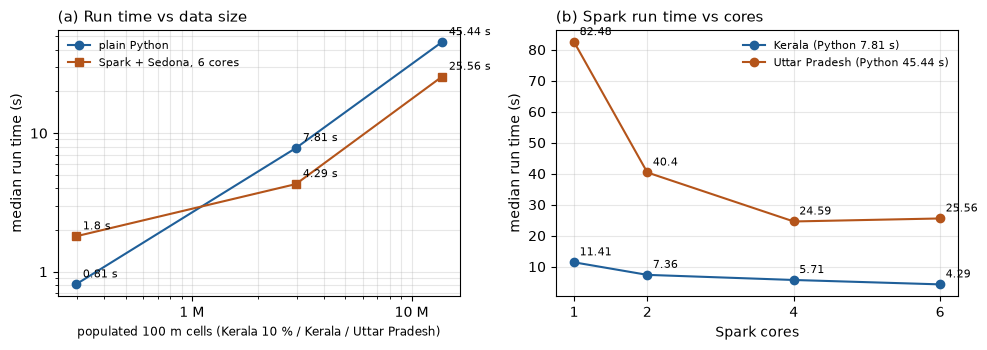

saved C:\Users\ASUS\Desktop\sem3\BIG SPATIAL DATA\PROJECT- SPATIAL INEQUALITY ASESSMENT\REPORT\figures\fig_benchmark.png


In [9]:
# Benchmark chart from the D10 results (notebook 30): (a) run time vs data size, (b) Spark run time vs cores
import matplotlib.ticker as mt
b = pd.read_csv(PROJECT / "FINAL COMPLETE DATASET" / "results" / "benchmarks" / "benchmarks.csv")
assert (b.status == "ok").all()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
py = b.query("engine == 'python'").sort_values("cells")
sp = b.query("engine == 'spark' and cores == 6").sort_values("cells")
ax[0].plot(py.cells, py.median_s, "o-", color="#1f5f99", label="plain Python")
ax[0].plot(sp.cells, sp.median_s, "s-", color="#b4541a", label="Spark + Sedona, 6 cores")
for t in (py, sp):
    for x, y in zip(t.cells, t.median_s):
        ax[0].annotate(f"{y:g} s", (x, y), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].xaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v / 1e6:g} M"))
ax[0].yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f"{v:g}"))
ax[0].set_xlabel("populated 100 m cells (Kerala 10 % / Kerala / Uttar Pradesh)", fontsize=8.5)
ax[0].set_ylabel("median run time (s)")
ax[0].set_title("(a) Run time vs data size", fontsize=11, loc="left")
ax[0].legend(fontsize=8, frameon=False); ax[0].grid(alpha=0.3, which="both")
for size, lab, c in [("kerala", "Kerala", "#1f5f99"), ("up", "Uttar Pradesh", "#b4541a")]:
    t = b.query("engine == 'spark' and size == @size").sort_values("cores")
    py_s = b.query("engine == 'python' and size == @size").median_s.iloc[0]
    ax[1].plot(t.cores, t.median_s, "o-", color=c, label=f"{lab} (Python {py_s:g} s)")
    for x, y in zip(t.cores, t.median_s):
        ax[1].annotate(f"{y:g}", (x, y), textcoords="offset points", xytext=(4, 5), fontsize=8)
ax[1].set_xticks([1, 2, 4, 6]); ax[1].set_xlabel("Spark cores"); ax[1].set_ylabel("median run time (s)")
ax[1].set_title("(b) Spark run time vs cores", fontsize=11, loc="left")
ax[1].legend(fontsize=8, frameon=False); ax[1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "fig_benchmark.png", dpi=200, facecolor="white")
plt.show()
print("saved", OUT / "fig_benchmark.png")